# FML 2026 Challenge: Analysis and Prediction over Bike Sharing Data

## Imports and Data Loading

In [697]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [698]:
df_bikes = pd.read_csv("../csv/bikes.csv")
df_bike_types = pd.read_csv("../csv/bike_types.csv")
df_stations = pd.read_csv("../csv/stations.csv")
df_cities = pd.read_csv("../csv/cities.csv")
df_stations_status = pd.read_csv("../csv/stations_status.csv")
df_trips_small = pd.read_csv("../csv/trips_small.csv")

## Data Exploration and Preprocessing Task

This part of the notebook presents an initial exploration and preprocessing of data from a bike-sharing system. It helps understand the structure, content, and quality of the different datasets before conducting further analysis.

For each dataset, several analyses are performed:

- previewing the first rows;
- examining data types and descriptive statistics;
- identifying missing values and duplicates;
- determining the number of unique values;
- analyzing key categorical and numerical variables;
- visualizing distributions using charts.

The visualizations mainly use bar charts, pie charts, and missing-value heatmaps created with Matplotlib and Seaborn.

### Exploration of `bikes.csv`

In [699]:
df_bikes.head()

,id,bike_type_id,computer_id
0,400481,196,83300002927
1,374044,204,7551171765
2,373778,204,7551140444
3,34749,14,0
4,88359,143,7551052355


In [700]:
df_bikes.info()

<class 'pandas.DataFrame'>
RangeIndex: 88436 entries, 0 to 88435
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            88436 non-null  int64
 1   bike_type_id  88436 non-null  int64
 2   computer_id   88436 non-null  int64
dtypes: int64(3)
memory usage: 2.0 MB


This table serves as an intermediate link between bikes and their corresponding types. No modifications were required, as all values are non-null and the data types are correct.

### Exploration of `bike_types.csv`

In [701]:
df_bike_types.head()

,id,vehicle_image,name,description,form_factor,rider_capacity,propulsion_type,max_range,battery_capacity
0,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [702]:
df_bike_types.info()

<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                121 non-null    int64  
 1   vehicle_image     91 non-null     str    
 2   name              91 non-null     str    
 3   description       51 non-null     str    
 4   form_factor       91 non-null     str    
 5   rider_capacity    91 non-null     float64
 6   propulsion_type   91 non-null     str    
 7   max_range         15 non-null     float64
 8   battery_capacity  22 non-null     float64
dtypes: float64(3), int64(1), str(5)
memory usage: 8.6 KB


In [703]:
df_bike_types[["rider_capacity", "max_range", "battery_capacity"]].describe()

,rider_capacity,max_range,battery_capacity
count,91.000000,15.0,22.000000
mean,1.230769,60000.0,547.727273
std,0.423659,0.0,61.638873
min,1.000000,60000.0,500.000000
25%,1.000000,60000.0,500.000000
50%,1.000000,60000.0,500.000000
75%,1.000000,60000.0,600.000000
max,2.000000,60000.0,690.000000


In [704]:
print("Number of duplicates : ", df_bike_types.duplicated().sum())

null_counts = df_bike_types.isnull().sum()
null_percentages = (null_counts / len(df_bike_types) * 100).round(2)
null_df = pd.DataFrame({
    "Number of null values": null_counts,
    "Percentage of null values (%)": null_percentages
})

print("Number of null values per column :")
print(null_df)

Number of duplicates :  0
Number of null values per column :
                  Number of null values  Percentage of null values (%)
id                                    0                           0.00
vehicle_image                        30                          24.79
name                                 30                          24.79
description                          70                          57.85
form_factor                          30                          24.79
rider_capacity                       30                          24.79
propulsion_type                      30                          24.79
max_range                           106                          87.60
battery_capacity                     99                          81.82


#### Missing Values Analysis and Handling

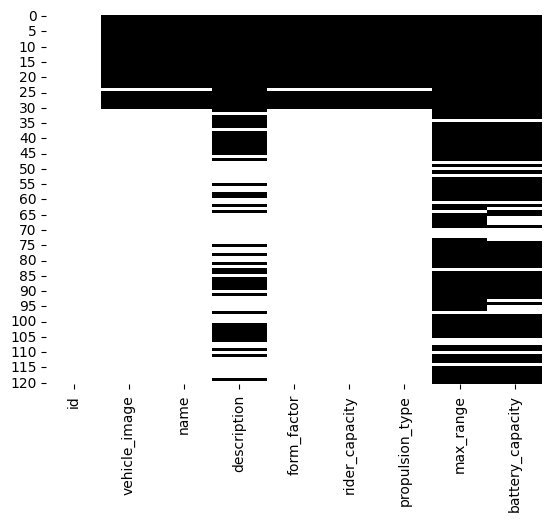

In [705]:
sns.heatmap(df_bike_types.isna(), cbar=False, cmap='binary')
plt.show()

In [706]:
for propulsion_type in ["electric_assist", "human"]:
    subset = df_bike_types[df_bike_types["propulsion_type"] == propulsion_type]
    null_counts = subset.isnull().sum()
    null_percentages = (null_counts / len(subset) * 100).round(2)

    result = pd.DataFrame({
        "Number of null values": null_counts,
        "Percentage of null values (%)": null_percentages
    })

    print(f"\nPropulsion type: {propulsion_type}")
    print(result)


Propulsion type: electric_assist
                  Number of null values  Percentage of null values (%)
id                                    0                           0.00
vehicle_image                         0                           0.00
name                                  0                           0.00
description                           5                          18.52
form_factor                           0                           0.00
rider_capacity                        0                           0.00
propulsion_type                       0                           0.00
max_range                            12                          44.44
battery_capacity                      5                          18.52

Propulsion type: human
                  Number of null values  Percentage of null values (%)
id                                    0                           0.00
vehicle_image                         0                           0.00
name               

We observe a significant number of missing values requiring different handling strategies:
- Completely empty rows: Several rows contain almost no information. We must first verify if their IDs are referenced in downstream tables (like `bikes` and `trips_small`). If unreferenced, they can be safely dropped. If they are actively linked, they must be kept to preserve referential integrity, with missing strings replaced by "Unknown" and numerical values by 0.
- Random absence: `description` values are missing randomly across all bike types and can be filled with "Unknown".
- Correlated absence: `max_range` and `battery_capacity` are structurally linked. They are logically 100% missing for the `human` propulsion type (which we will fill with 0). However, they are also unexpectedly missing for a significant portion of the `electric_assist` fleet, which we will impute using the mean of the available electric bikes.

In [707]:
# Impute missing values with the means for electric_assist propulsion types
cols = ["max_range", "battery_capacity"]
mask = df_bike_types["propulsion_type"] == "electric_assist"

df_bike_types.loc[mask, cols] = df_bike_types.loc[mask, cols].fillna(df_bike_types.loc[mask, cols].mean())

In [708]:
# Check if the rows with all columns empty are used in df_bikes
empty_rows = df_bike_types[df_bike_types.isnull().sum(axis=1) == 8]
print("Number of rows with all columns empty : ", len(empty_rows))

ids_used = empty_rows[empty_rows["id"].isin(df_bikes["bike_type_id"])]
print("Number of id used in df_bikes : ", len(ids_used))

Number of rows with all columns empty :  30
Number of id used in df_bikes :  30


In [709]:
# Fill all missing values with "Unknown" for string columns and 0 for numeric columns
string_cols = ["vehicle_image", "name", "description", "form_factor", "propulsion_type"]
numeric_cols = ["rider_capacity", "max_range", "battery_capacity"]

df_bike_types[string_cols] = df_bike_types[string_cols].fillna("Unknown")
df_bike_types[numeric_cols] = df_bike_types[numeric_cols].fillna(0)

In [710]:
# Check if there are still any missing values
df_bike_types.isnull().sum()

id                  0
vehicle_image       0
name                0
description         0
form_factor         0
rider_capacity      0
propulsion_type     0
max_range           0
battery_capacity    0
dtype: int64

#### Standardization of Bike Types

##### Column: `name`

In [711]:
df_bike_types["name"].unique()

<StringArray>
[                        'Unknown',                         'Comfort',
   'Rower z fotelikiem dziecięcym',                          'Tandem',
                 'Elektricno kolo',                     'e-CARGObike',
            'Rowerek dziecięcy 6+',     '3-rychlostní SMARTbike 2.0.',
       'e-SMARTbike 2.0 with RFID',         '28 Zoll - Tourenfahrrad',
                'e-SMARTbike 2.0.',          'Smartbike 2.0 (B) 2019',
                 'e-SMARTbike 1.0',                       'UsedomRad',
               'UsedomRad Classic',         '20 Zoll - Kinderfahrrad',
         '24 Zoll - Kinderfahrrad',                 'Z wałem kardana',
          '7-rychlostní SMARTbike',                 'e-Bike "LaBigi"',
                          'E-Bike',     '7-rychlostní SMARTbike 2.0.',
                     'e-Cargobike',                       'CARGObike',
     '8-rychlostní SMARTbike 2.0.',                  'with Framelock',
          '8-rychlostní SMARTbike',            'CARGObike (3 wh

##### Column: `propulsion_type`

In [712]:
print(df_bike_types["propulsion_type"].unique())
df_bike_types.loc[df_bike_types["propulsion_type"] == "electric_assist", "propulsion_type"] = "electric"

<StringArray>
['Unknown', 'human', 'electric_assist']
Length: 3, dtype: str


##### Column: `form_factor`

In [713]:
print(df_bike_types["form_factor"].unique())
df_bike_types.loc[df_bike_types["form_factor"] == "bicycle", "form_factor"] = "regular"
df_bike_types.loc[df_bike_types["form_factor"] == "cargo_bicycle", "form_factor"] = "cargo"

<StringArray>
['Unknown', 'bicycle', 'cargo_bicycle', 'other']
Length: 4, dtype: str


In [714]:
# Since there are only one row with the value "other", and we have information about the bike
# We can assume it's a regular bike
df_bike_types.loc[df_bike_types["form_factor"] == "other", "form_factor"] = "regular"

#### Dataset Visualizations

[Text(0.5, 1.0, 'Count of Bike Types'),
 Text(0.5, 0, 'Count'),
 Text(0, 0.5, 'Bike Type')]

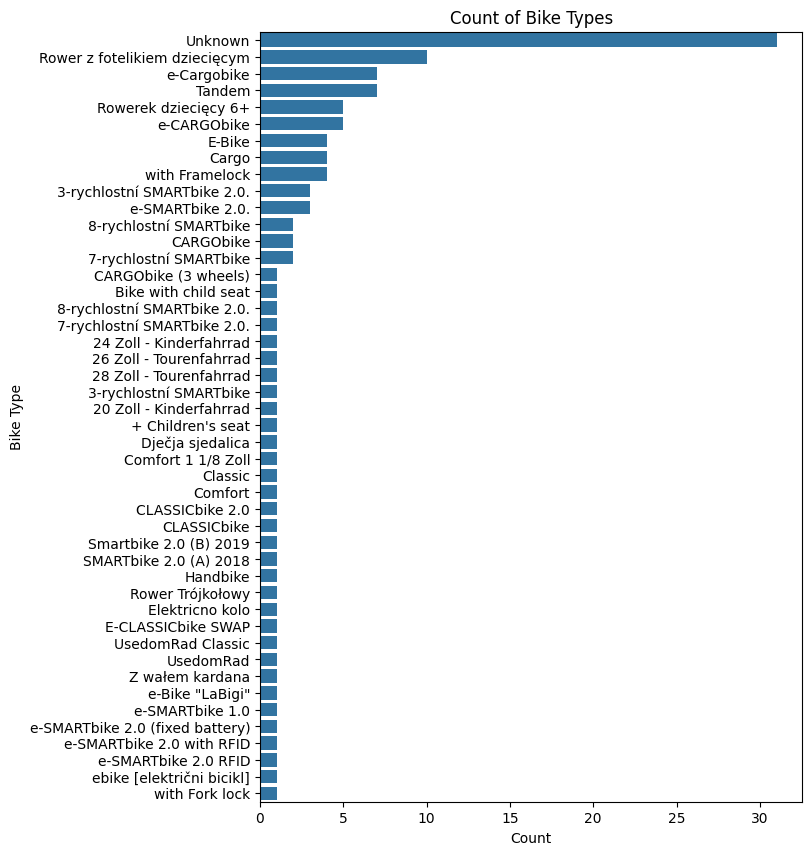

In [715]:
df_count = df_bike_types.groupby('name')["name"].count()
df_count = df_count.sort_values(ascending=False)

plt.figure(figsize=(7, 10))
sns_bar = sns.barplot(y=df_count.index, x=df_count.values)
sns_bar.set(
    title="Count of Bike Types",
    xlabel="Count", 
    ylabel="Bike Type"
)

propulsion_type
Unknown     30
electric    27
human       64
Name: propulsion_type, dtype: int64 

form_factor
Unknown    30
cargo      19
regular    72
Name: form_factor, dtype: int64


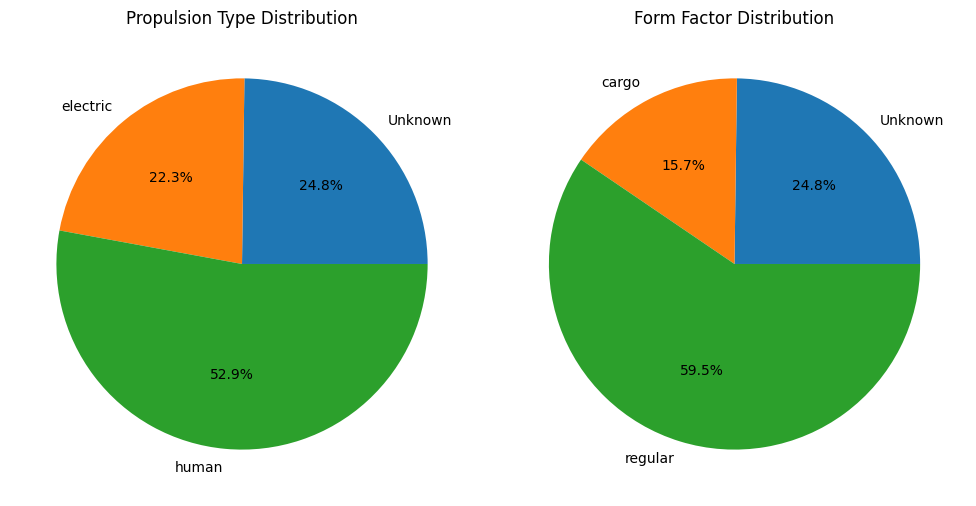

In [716]:
propulsion = df_bike_types.groupby('propulsion_type')["propulsion_type"].count()
print(propulsion, '\n')

grouped_form = df_bike_types.groupby("form_factor")["form_factor"].count()
print(grouped_form)


fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))

propulsion.plot(kind="pie", autopct="%1.1f%%",  ax=axes[0])
axes[0].set_title("Propulsion Type Distribution")

grouped_form.plot(kind="pie", autopct="%1.1f%%", ax=axes[1])
axes[1].set_title("Form Factor Distribution")

plt.tight_layout()
plt.show()

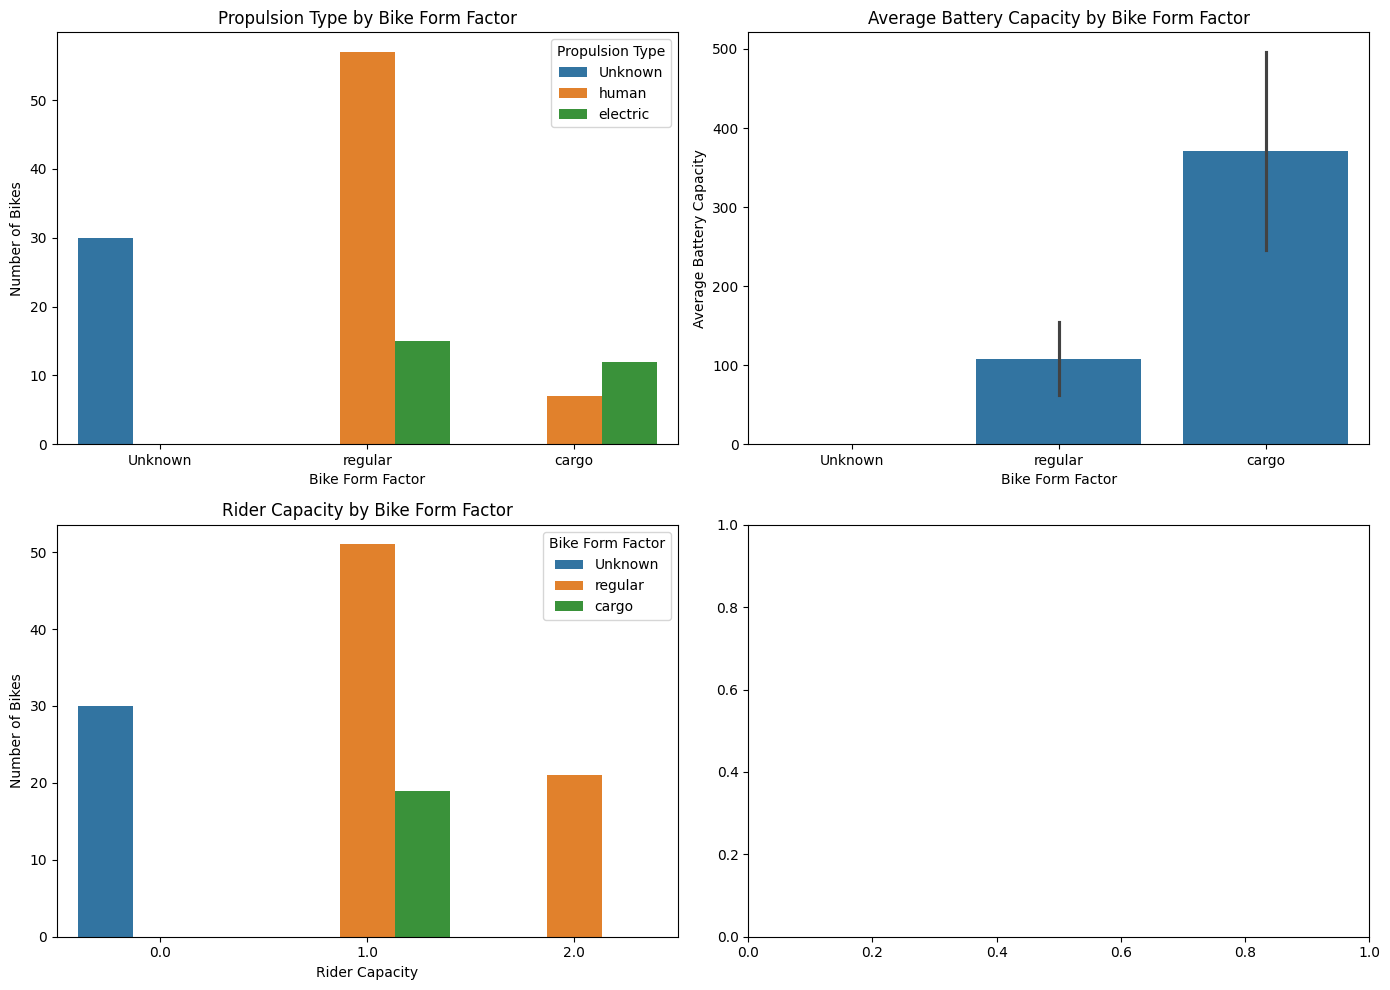

In [717]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(
    data=df_bike_types,
    x="form_factor",
    hue="propulsion_type",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Propulsion Type by Bike Form Factor")
axes[0, 0].set_xlabel("Bike Form Factor")
axes[0, 0].set_ylabel("Number of Bikes")
axes[0, 0].legend(title="Propulsion Type")

sns.barplot(
    data=df_bike_types,
    x="form_factor",
    y="battery_capacity",
    estimator="mean",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Average Battery Capacity by Bike Form Factor")
axes[0, 1].set_xlabel("Bike Form Factor")
axes[0, 1].set_ylabel("Average Battery Capacity")

sns.countplot(
    data=df_bike_types,
    x="rider_capacity",
    hue="form_factor",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Rider Capacity by Bike Form Factor")
axes[1, 0].set_xlabel("Rider Capacity")
axes[1, 0].set_ylabel("Number of Bikes")
axes[1, 0].legend(title="Bike Form Factor")

plt.tight_layout()
plt.show()

### Exploration of `stations.csv`

In [718]:
df_stations.head()

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat
0,142186362,135,BIKE 500100,0,NaN,12,0,0,NaN,7.821669,51.677449
1,940986,176,Bahnhof Trassenmoor 5525,5525,NaN,0,6,0,NaN,13.868973,54.090538
2,93646685,176,Mutter/Vater-Kind-Kurklinik Haus Möwennest Zin...,5529,stele,0,15,0,NaN,13.918970,54.073088
3,111365509,243,Station Road,8494,smart_sign,0,20,0,NaN,-3.936120,56.119272
4,405835,302,Birkirkara Road,6868,sign,0,6,0,NaN,14.481456,35.906836


In [719]:
df_stations.info()

<class 'pandas.DataFrame'>
RangeIndex: 2932 entries, 0 to 2931
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2932 non-null   int64  
 1   city_id        2932 non-null   int64  
 2   name           2932 non-null   str    
 3   app_number     2932 non-null   int64  
 4   terminal_type  2345 non-null   str    
 5   place_type     2932 non-null   int64  
 6   bike_racks     2932 non-null   int64  
 7   special_racks  2932 non-null   int64  
 8   rack_locks     0 non-null      float64
 9   lon            2932 non-null   float64
 10  lat            2932 non-null   float64
dtypes: float64(3), int64(6), str(2)
memory usage: 252.1 KB


In [720]:
# Calculate the total number of racks 
df_stations["total_racks"] = df_stations["bike_racks"] + df_stations["special_racks"]

df_stations[["total_racks", "bike_racks", "special_racks"]].describe()

,total_racks,bike_racks,special_racks
count,2932.000000,2932.000000,2932.000000
mean,6.022169,6.033424,-0.011255
std,6.502278,6.495116,0.486820
min,0.000000,0.000000,-10.000000
25%,0.000000,0.000000,0.000000
50%,5.000000,6.000000,0.000000
75%,10.000000,10.000000,0.000000
max,70.000000,70.000000,12.000000


In [721]:
print(df_stations["terminal_type"].unique(), '\n')
print(df_stations["place_type"].unique(), '\n')

print("Number of duplicate rows in df_stations:", df_stations.duplicated().sum())

<StringArray>
[             nan,          'stele',     'smart_sign',           'sign',
          '7inch',           'free',      'character',   'traffic_sign',
            'mmt', 'terminal_sleek',           'pult']
Length: 11, dtype: str 

[12  0  6 14  8  7 21 17 16 26 15  4 18 19 27  3] 

Number of duplicate rows in df_stations: 0


#### Missing Values Analysis and Handling

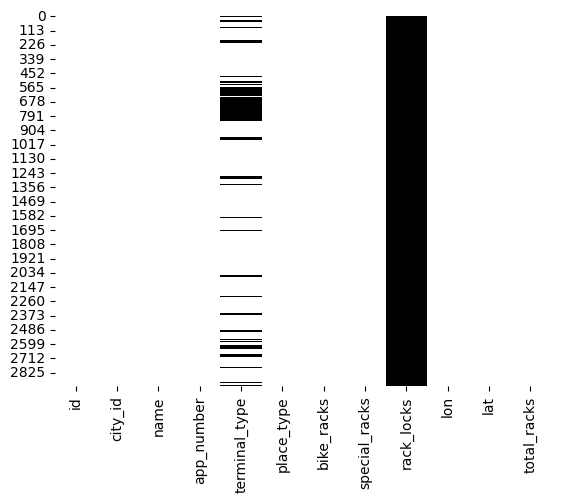

In [722]:
sns.heatmap(df_stations.isna(), cbar=False, cmap='binary')
plt.show()

We observe that the entire `rack_locks` column is missing, so we can drop it. Additionally, there are missing values in the `terminal_type` column, we replace null values with "Unknown" to create a dedicated category and prevent issues during subsequent dataset merging.

In [723]:
# Drop the 'rack_locks' column 
df_stations = df_stations.drop('rack_locks', axis=1)

In [724]:
# Replace missing values in 'terminal_type' with "Unknown"
df_stations["terminal_type"] = df_stations["terminal_type"].fillna("Unknown")

In [725]:
# Check if there are still any missing values
df_stations.isnull().sum()

id               0
city_id          0
name             0
app_number       0
terminal_type    0
place_type       0
bike_racks       0
special_racks    0
lon              0
lat              0
total_racks      0
dtype: int64

#### Dataset Visualizations

[Text(0.5, 1.0, 'Count of Terminal Types'),
 Text(0, 0.5, 'Terminal Type'),
 Text(0.5, 0, 'Count')]

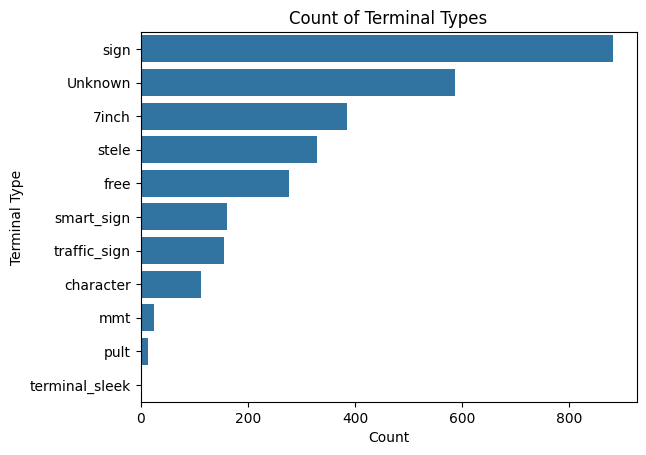

In [726]:
stations_count = df_stations['terminal_type'].value_counts()
sns_barplot = sns.barplot(
    y=stations_count.index,
    x=stations_count.values
    )
sns_barplot.set(
    title="Count of Terminal Types",
    ylabel="Terminal Type", 
    xlabel="Count"
)

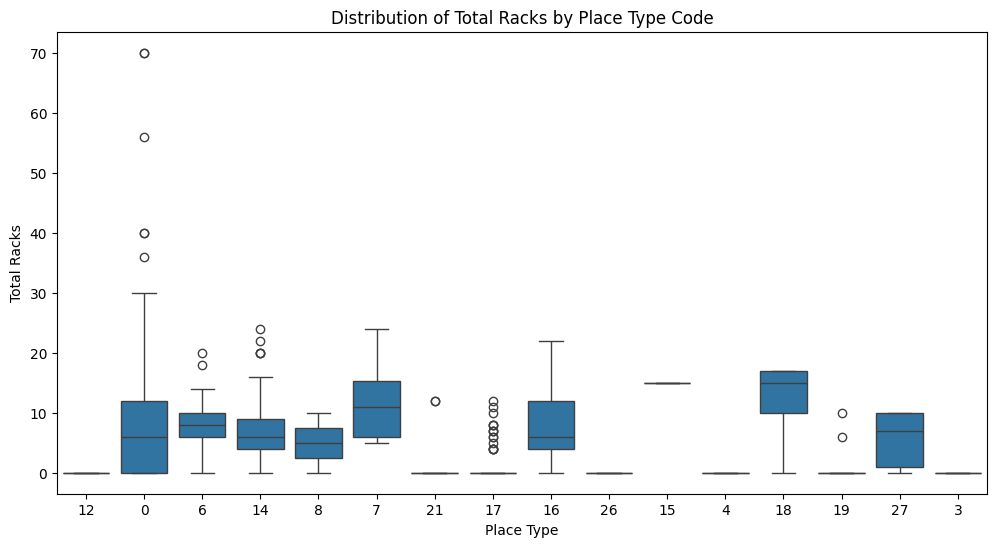

In [727]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_stations, 
    x=df_stations['place_type'].astype(str), 
    y='total_racks'
)
plt.title("Distribution of Total Racks by Place Type Code")
plt.xlabel("Place Type")
plt.ylabel("Total Racks")
plt.show()

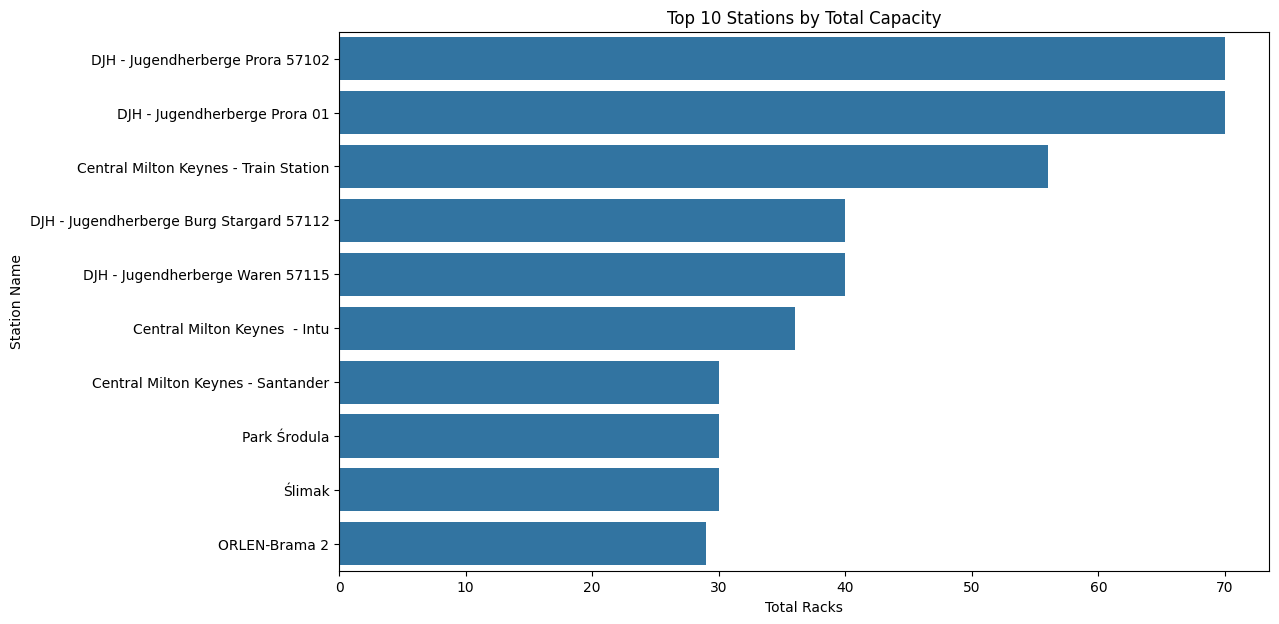

In [728]:
top_stations = df_stations.sort_values('total_racks', ascending=False).head(10)

plt.figure(figsize=(12, 7))
sns.barplot(data=top_stations, x='total_racks', y='name')
plt.title("Top 10 Stations by Total Capacity")
plt.xlabel("Total Racks")
plt.ylabel("Station Name")

plt.show()

### Exploration of `stations_status.csv`

In [729]:
df_stations_status.head()

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
0,101896428,1.661530e+09,2,0,2,0,0,False
1,54643,1.661531e+09,1,0,1,0,0,False
2,6201611,1.661531e+09,3,0,3,0,0,False
3,294346,1.661531e+09,8,0,8,0,0,False
4,781866,1.661531e+09,1,1,0,5,0,False


In [730]:
df_stations_status.info()

<class 'pandas.DataFrame'>
RangeIndex: 2925967 entries, 0 to 2925966
Data columns (total 8 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   station_id               int64  
 1   time                     float64
 2   bikes                    int64  
 3   booked_bikes             int64  
 4   bikes_available_to_rent  int64  
 5   free_racks               int64  
 6   free_special_racks       int64  
 7   maintenance              bool   
dtypes: bool(1), float64(1), int64(6)
memory usage: 159.1 MB


#### Cleaning Data Types
We observe that the time column is in seconds and difficult to read, so we convert time into a datetime format and extract the day, month, and hour.

In [731]:
# 1. Convert numeric UTC timestamp (seconds) to UTC datetime
df_stations_status['datetime'] = pd.to_datetime(df_stations_status['time'], unit='s', utc=True)

# 2. Extract separate numeric day and hour columns
df_stations_status['month']        = df_stations_status['datetime'].dt.month       # 1 to 12
df_stations_status['day_of_month'] = df_stations_status['datetime'].dt.day         # 1 to 31
df_stations_status['hour']         = df_stations_status['datetime'].dt.hour        # 0 to 23

df_stations_status.head()

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,datetime,month,day_of_month,hour
0,101896428,1.661530e+09,2,0,2,0,0,False,2022-08-26 16:14:01+00:00,8,26,16
1,54643,1.661531e+09,1,0,1,0,0,False,2022-08-26 16:15:01+00:00,8,26,16
2,6201611,1.661531e+09,3,0,3,0,0,False,2022-08-26 16:15:01+00:00,8,26,16
3,294346,1.661531e+09,8,0,8,0,0,False,2022-08-26 16:15:01+00:00,8,26,16
4,781866,1.661531e+09,1,1,0,5,0,False,2022-08-26 16:15:01+00:00,8,26,16


### Exploration of `cities.csv`

In [732]:
df_cities.head()

,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False


In [733]:
df_cities.info()

<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       267 non-null    int64  
 1   name                     267 non-null    str    
 2   lat                      267 non-null    float64
 3   lon                      267 non-null    float64
 4   timezone                 267 non-null    str    
 5   country                  267 non-null    str    
 6   return_to_official_only  267 non-null    bool   
dtypes: bool(1), float64(2), int64(1), str(3)
memory usage: 12.9 KB


In [734]:
print("Number of duplicate: ", df_cities.duplicated().sum())
print("Number of unique timezones:", len(df_cities["timezone"].unique()))

Number of duplicate:  0
Number of unique timezones: 9


#### Dataset Visualizations

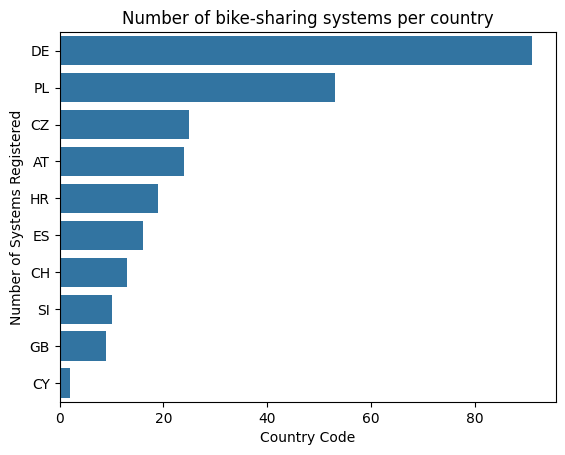

In [735]:
# Vizualization 
cities_top = df_cities["country"].value_counts().reset_index().head(10)

sns_bar = sns.barplot(
    data=cities_top,
    x="count",
    y="country"
)

sns_bar.set(
    title="Number of bike-sharing systems per country",
    xlabel="Country Code", 
    ylabel="Number of Systems Registered"
)

plt.show()

return_to_official_only
False     67
True     200
Name: return_to_official_only, dtype: int64


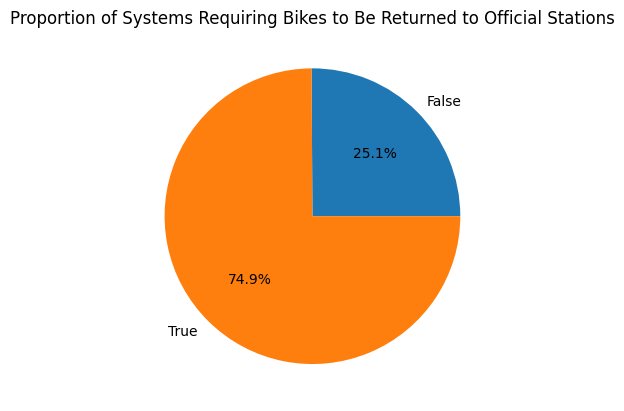

In [736]:
official_only = df_cities.groupby("return_to_official_only")["return_to_official_only"].count()
print(official_only)

official_only.plot(kind='pie', autopct="%1.1f%%")
plt.title("Proportion of Systems Requiring Bikes to Be Returned to Official Stations")
plt.show()


### Exploration of `trips_small.csv`

In [737]:
df_trips_small.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993


In [738]:
df_trips_small.info()

<class 'pandas.DataFrame'>
RangeIndex: 1161376 entries, 0 to 1161375
Data columns (total 13 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   bike_id           1161376 non-null  int64  
 1   city_id           1161376 non-null  int64  
 2   time_start        1161376 non-null  float64
 3   lon_start         1161376 non-null  float64
 4   lat_start         1161376 non-null  float64
 5   lon_end           1161376 non-null  float64
 6   lat_end           1161376 non-null  float64
 7   station_id_start  1072161 non-null  float64
 8   station_id_end    1039472 non-null  float64
 9   battery_start     168532 non-null   float64
 10  battery_end       168641 non-null   float64
 11  duration          1161376 non-null  float64
 12  distance          1161376 non-null  float64
dtypes: float64(11), int64(2)
memory usage: 115.2 MB


In [739]:
df_trips_small[["battery_start", "battery_end", "duration", "distance"]].describe()

,battery_start,battery_end,duration,distance
count,168532.000000,168641.000000,1.161376e+06,1.161376e+06
mean,80.988697,76.688996,1.256241e+03,1.791774e+03
std,21.384192,22.615122,1.980838e+03,1.495191e+03
min,0.000000,0.000000,1.210000e+02,5.001365e+01
25%,66.000000,61.000000,4.800000e+02,8.851685e+02
50%,89.000000,83.000000,7.200000e+02,1.346711e+03
75%,100.000000,97.000000,1.200000e+03,2.238540e+03
max,100.000000,100.000000,2.874000e+04,1.999946e+04


In [740]:
print("Number of duplicate: ", df_trips_small.duplicated().sum())
print("Number of null values per column :")
print(df_trips_small.isnull().sum())

Number of duplicate:  0
Number of null values per column :
bike_id                  0
city_id                  0
time_start               0
lon_start                0
lat_start                0
lon_end                  0
lat_end                  0
station_id_start     89215
station_id_end      121904
battery_start       992844
battery_end         992735
duration                 0
distance                 0
dtype: int64


#### Cleaning Data Types

To clean the trips_small dataset, we have to apply a few changes:
- Convert `station_id_start` and `station_id_end` from floats to integers
- Transform `time_start` into datetime and `duration` in minutes
- Convert `distance` into kilometers for easier analysis

In [741]:
# Convert station_id_start and station_id_end to integers 
df_trips_small["station_id_start"] = df_trips_small["station_id_start"].astype('Int64')
df_trips_small["station_id_end"] = df_trips_small["station_id_end"].astype('Int64')

# Transform time_start into datetime and duration in minutes
df_trips_small['time_start_dt'] = pd.to_datetime(df_trips_small['time_start'], unit='s', utc=True)
df_trips_small['time_start_month'] = df_trips_small['time_start_dt'].dt.month
df_trips_small['time_start_day'] = df_trips_small['time_start_dt'].dt.day
df_trips_small['time_start_hour'] = df_trips_small['time_start_dt'].dt.hour
df_trips_small['time_start_minute'] = df_trips_small['time_start_dt'].dt.minute

df_trips_small['duration_min'] = df_trips_small['duration'] / 60

# Convert distance to kilometers 
df_trips_small['distance_km'] = df_trips_small['distance'] / 1000.0

df_trips_small.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance,time_start_dt,time_start_month,time_start_day,time_start_hour,time_start_minute,duration_min,distance_km
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480,<NA>,NaN,NaN,360.0,135.879806,2022-11-25 11:48:01+00:00,11,25,11,48,6.0,0.135880
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472,4775153,NaN,NaN,1920.0,3301.514764,2022-12-01 12:21:01+00:00,12,1,12,21,32.0,3.301515
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153,<NA>,NaN,NaN,780.0,115.020620,2022-12-05 14:52:01+00:00,12,5,14,52,13.0,0.115021
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087,87796883,NaN,NaN,540.0,1643.609250,2022-12-06 17:43:01+00:00,12,6,17,43,9.0,1.643609
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883,87796472,NaN,NaN,4680.0,897.351993,2022-12-20 05:28:01+00:00,12,20,5,28,78.0,0.897352


#### Missing Values Analysis and Handling

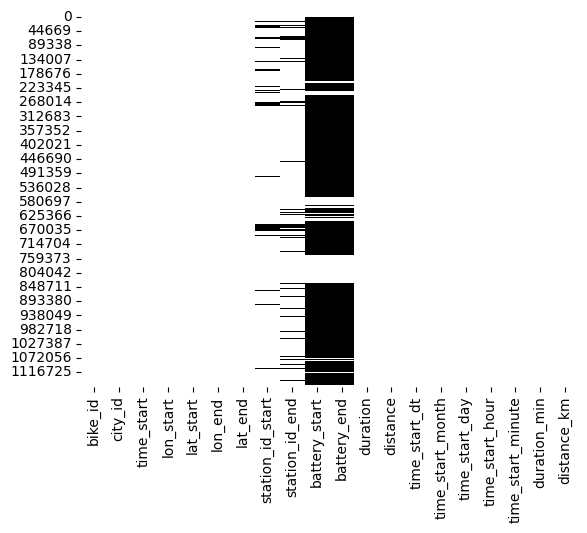

In [742]:
sns.heatmap(df_trips_small.isna(), cbar=False, cmap='binary')
plt.show()

The number of missing values in the `battery_start` and `battery_end` columns is very high. However, these columns are relevant only for electric bikes, so we have to look at the number of missing values in these columns for electric bikes only. 

Regarding the missing values in `station_id_start` and `station_id_end`, the documentation indicates that these `NaN` values correspond to free-floating trips rather than data collection errors. Therefore, we chose to retain these missing values and introduce a new categorical column to clearly distinguish between station-based and free-floating trips

In [ ]:
# Merging df_trips_small with df_bikes and df_bike_types to get only the electric bikes
bike_sub = df_bikes[['id', 'bike_type_id']]
bike_type_sub = df_bike_types[['id', 'propulsion_type']]
trips_small_sub = df_trips_small[["bike_id", "battery_start", "battery_end"]]

trips_with_bikes = pd.merge(trips_small_sub, bike_sub, left_on='bike_id', right_on='id', how='left')

trips_with_bike_types = pd.merge(trips_with_bikes, bike_type_sub, left_on="bike_type_id", right_on="id", how="left")
trips_with_bike_types = trips_with_bike_types.drop(columns=['id_x', 'id_y'])

trips_with_bike_types

# Compter les valeurs manquantes de batterie en fonction du type de propulsion
missing_battery_analysis = trips_with_bike_types.groupby('propulsion_type')[['battery_start', 'battery_end']].apply(lambda x: x.isnull().sum())

print("Nombre de valeurs manquantes par type de propulsion :")
print(missing_battery_analysis)

# Compter aussi le nombre total de trajets pour chaque type pour comparer
print("\nNombre total de trajets par type de propulsion :")
print(trips_with_bike_types['propulsion_type'].value_counts())

Nombre de valeurs manquantes par type de propulsion :
                 battery_start  battery_end
propulsion_type                            
Unknown                   2346         2346
electric                 11861        11752
human                   978637       978637

Nombre total de trajets par type de propulsion :
propulsion_type
human       978939
electric    180091
Unknown       2346
Name: count, dtype: int64


In [743]:
# New columns to distinguish station-based and free-floating trips
df_trips_small['trip_type_start'] = df_trips_small['station_id_start'].apply(
    lambda x: 'Station' if pd.notnull(x) else 'Free-floating'
)

df_trips_small['trip_type_end'] = df_trips_small['station_id_end'].apply(
    lambda x: 'Station' if pd.notnull(x) else 'Free-floating'
)

df_trips_small.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,...,distance,time_start_dt,time_start_month,time_start_day,time_start_hour,time_start_minute,duration_min,distance_km,trip_type_start,trip_type_end
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480,<NA>,NaN,...,135.879806,2022-11-25 11:48:01+00:00,11,25,11,48,6.0,0.135880,Station,Free-floating
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472,4775153,NaN,...,3301.514764,2022-12-01 12:21:01+00:00,12,1,12,21,32.0,3.301515,Station,Station
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153,<NA>,NaN,...,115.020620,2022-12-05 14:52:01+00:00,12,5,14,52,13.0,0.115021,Station,Free-floating
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087,87796883,NaN,...,1643.609250,2022-12-06 17:43:01+00:00,12,6,17,43,9.0,1.643609,Station,Station
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883,87796472,NaN,...,897.351993,2022-12-20 05:28:01+00:00,12,20,5,28,78.0,0.897352,Station,Station


## Merge tables

In [ ]:
# Assembling a complete dataframe with trips, bikes and bike types information


,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,...,duration_min,distance_km,trip_type_start,trip_type_end,bike_type_id,name,form_factor,propulsion_type,max_range,battery_capacity
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480,<NA>,NaN,...,6.0,0.135880,Station,Free-floating,15,with Fork lock,regular,human,0.0,0.0
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472,4775153,NaN,...,32.0,3.301515,Station,Station,15,with Fork lock,regular,human,0.0,0.0
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153,<NA>,NaN,...,13.0,0.115021,Station,Free-floating,15,with Fork lock,regular,human,0.0,0.0
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087,87796883,NaN,...,9.0,1.643609,Station,Station,15,with Fork lock,regular,human,0.0,0.0
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883,87796472,NaN,...,78.0,0.897352,Station,Station,15,with Fork lock,regular,human,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1161371,840054,679,1.684753e+09,-3.174022,51.438833,-3.163247,51.465538,30005988,88102363,100.0,...,22.0,3.061892,Station,Station,182,e-SMARTbike 2.0 with RFID,regular,electric,60000.0,500.0
1161372,840054,679,1.685088e+09,-3.166644,51.446057,-3.163247,51.465538,6270602,88102363,100.0,...,13.0,2.178941,Station,Station,182,e-SMARTbike 2.0 with RFID,regular,electric,60000.0,500.0
1161373,840054,679,1.686059e+09,-3.174022,51.438833,-3.163247,51.465538,30005988,88102363,100.0,...,15.0,3.061892,Station,Station,182,e-SMARTbike 2.0 with RFID,regular,electric,60000.0,500.0
1161374,840054,679,1.686121e+09,-3.185756,51.429879,-3.163247,51.465538,86312067,88102363,87.0,...,17.0,4.260899,Station,Station,182,e-SMARTbike 2.0 with RFID,regular,electric,60000.0,500.0


In [745]:
# Filter to get only electric bikes and see if we can drop the columns battery_start and battery_end 
electric_df = complete_df.groupby("propulsion_type")
electric_df = complete_df[complete_df["propulsion_type"] == "electric"]

electric_df.info()

# We can't

<class 'pandas.DataFrame'>
Index: 180091 entries, 10159 to 1161375
Data columns (total 28 columns):
 #   Column             Non-Null Count   Dtype             
---  ------             --------------   -----             
 0   bike_id            180091 non-null  int64             
 1   city_id            180091 non-null  int64             
 2   time_start         180091 non-null  float64           
 3   lon_start          180091 non-null  float64           
 4   lat_start          180091 non-null  float64           
 5   lon_end            180091 non-null  float64           
 6   lat_end            180091 non-null  float64           
 7   station_id_start   171255 non-null  Int64             
 8   station_id_end     169293 non-null  Int64             
 9   battery_start      168230 non-null  float64           
 10  battery_end        168339 non-null  float64           
 11  duration           180091 non-null  float64           
 12  distance           180091 non-null  float64           


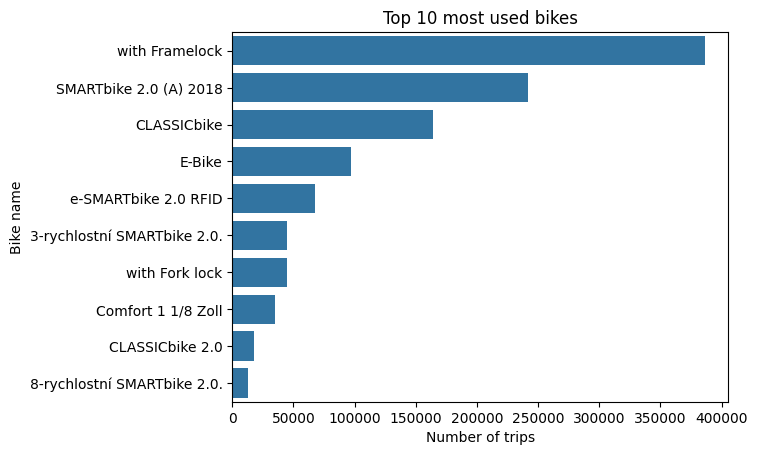

In [746]:
top_bikes = complete_df['name'].value_counts().head(10).reset_index()
top_bikes.columns = ['name', 'count']

plt.figure()
top_bikes_barplot = sns.barplot(data=top_bikes, x='count', y='name')
top_bikes_barplot.set_title("Top 10 most used bikes")
top_bikes_barplot.set_xlabel("Number of trips")
top_bikes_barplot.set_ylabel("Bike name")
plt.show()

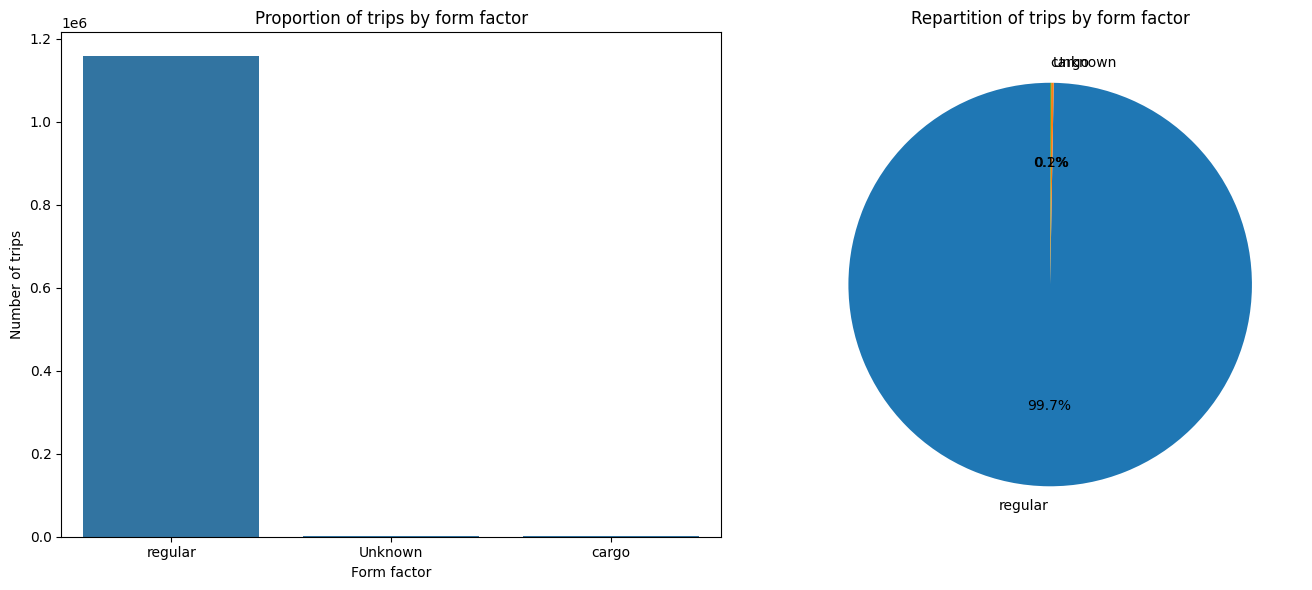

In [747]:
form_counts = complete_df['form_factor'].value_counts().reset_index()
form_counts.columns = ['form_factor', 'count']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(data=form_counts, x='form_factor', y='count', ax=axes[0])
axes[0].set_title("Proportion of trips by form factor")
axes[0].set_xlabel("Form factor")
axes[0].set_ylabel("Number of trips")

complete_df['form_factor'].value_counts().plot(
    kind='pie', 
    autopct='%1.1f%%', 
    startangle=90, 
    ax=axes[1]
)
axes[1].set_title("Repartition of trips by form factor")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()